# 10 · Dos jugadores: self-play e información oculta
**Entorno:** MiniCartas (mazos espejo `aggro`) · **Tiempo de ejecución:** ≤ 6 min en CPU · **Criterio de la lección:** el agente de self-play le gana ≥ 90 % al aleatorio (LB del IC 95 %, n = 1000 partidas, 500 por asiento)
y las cotas de información oculta (R23) no se violan nunca en 1000 partidas.

## 1. La idea en una frase
En un juego de dos jugadores el mejor rival para aprender es **uno mismo**: el mismo modelo juega ambos asientos con recompensa +1 / 0 / −1, y lo que no se ve del rival se trata con **hechos y cotas demostrables**, no con priors.

**En el sistema de Luca:** self-play con PPO + GAE y recompensa pura +1/0/−1; la información oculta se modela solo con hechos (lo que el rival ya reveló) y cotas, sin priors bayesianos.
**En un problema de negocio:** un simulador con un competidor (otra flota, otra plataforma) que también aprende; y datos faltantes que se acotan con lo que sí se sabe con certeza.

## 2. La intuición y la fórmula
**Self-play.** Cada partida es de autojuego puro (ambos asientos con el modelo vivo, se entrenan ambos flujos de decisiones) o del modelo vivo contra un **snapshot** reciente
de sí mismo (para no sobreajustarse a su versión actual). La recompensa es terminal: $+1$ al ganador y $-1$ al perdedor, asignada a la última decisión de cada jugador, y GAE reparte el crédito hacia atrás.

**Información oculta.** No sabemos qué hay en la mano, el mazo ni los premios del rival, pero sí lo que reveló: criaturas en juego, energías unidas y descarte. Con $c_t$ el máximo de copias del tipo $t$ en cualquier mazo
y $\ell_t$ las copias reveladas, valen dos hechos: **cota inferior** (hay al menos $\ell_t$ del tipo $t$) y **cota superior** de lo no revelado, $u_t = \max(0,\, c_t - \ell_t)$.
Un *prior* en cambio *supone* una distribución de mazos y puede dar estimaciones imposibles.

In [1]:
import os
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, BatchObs, seed_everything
from rlf.eval.stats import mean_ci, proportion_ci, passes_lower
from rlf.eval.arena import play_games
from rlf.envs.cartas import ARCHETYPES, MAXC, CartasEnv, rival_bounds
from rlf.agents.baselines import RandomPolicy
from rlf.agents.policy import ActorCriticPolicy
from rlf.agents.ppo import PPOConfig, SelfPlay
from rlf.nets.tokens import MiniPTCGNet
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
make_env = lambda: CartasEnv()             # mazos espejo aggro
AGGRO = np.array(ARCHETYPES["aggro"])

## 3. El núcleo: las cotas de información oculta
Escritas a mano desde el estado del juego y comparadas con `rival_bounds` de `rlf`.

In [2]:
def bounds_by_hand(env, player):
    """lower[t]: copias del tipo t que el rival reveló (tablero + energías unidas + descarte); upper[t] = max(0, MAXC[t] − lower[t])."""
    core, rival = env.core, 1 - player
    lower = np.zeros(7, dtype=np.int64)
    for slot in core.board[rival]:
        if slot is not None:
            lower[slot[0]] += 1          # la criatura en juego
            lower[4] += slot[2]          # sus energías unidas (tipo 4 = Energía)
    for card in core.discard[rival]:
        lower[card] += 1                 # cartas ya descartadas
    return lower, np.maximum(0, MAXC - lower)

rng = np.random.default_rng(TRAIN_SEED)
env = make_env(); obs = env.reset(EVAL_SEED_BASE)
for _ in range(25):
    obs = env.step(int(rng.integers(obs.n_options))).obs
    if obs.n_options == 0:
        break
lo_a, up_a = bounds_by_hand(env, 0)
lo_b, up_b = rival_bounds(env, 0)
assert np.array_equal(lo_a, lo_b) and np.array_equal(up_a, up_b)
print("cotas del rival del jugador 0 a mitad de una partida:\n  lower", lo_a.tolist(), "\n  upper", up_a.tolist(), "\n  (MAXC ", MAXC.tolist(), ")")

cotas del rival del jugador 0 a mitad de una partida:
  lower [1, 2, 0, 0, 4, 2, 0] 
  upper [5, 1, 5, 3, 4, 1, 4] 
  (MAXC  [6, 3, 5, 3, 8, 3, 4] )


## 4. Entrenar y graficar la curva de aprendizaje
Self-play con el mini-PTCGNet (lección 9): 200 000 decisiones de entrenamiento, 64 partidas en paralelo, pool de 4 snapshots, mitad de autojuego puro. Cada cierto número de decisiones medimos la tasa de
victoria contra `RandomPolicy` (n = 1000, 500 por asiento).

  10000 decisiones (  327 partidas,   11 s): tasa de victoria vs aleatorio 0.972  IC95 [0.960, 0.981]


  20000 decisiones (  717 partidas,   20 s): tasa de victoria vs aleatorio 0.989  IC95 [0.980, 0.994]


  40000 decisiones ( 1558 partidas,   37 s): tasa de victoria vs aleatorio 0.986  IC95 [0.977, 0.992]


  80000 decisiones ( 3047 partidas,   68 s): tasa de victoria vs aleatorio 0.986  IC95 [0.977, 0.992]


 120000 decisiones ( 4472 partidas,   99 s): tasa de victoria vs aleatorio 0.989  IC95 [0.980, 0.994]


 200000 decisiones ( 7385 partidas,  160 s): tasa de victoria vs aleatorio 0.976  IC95 [0.965, 0.984]


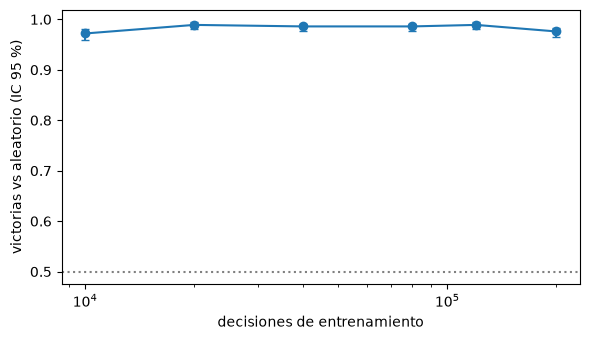

In [3]:
N = 1000
torch.manual_seed(TRAIN_SEED)
net = MiniPTCGNet(make_env().spec)
sp = SelfPlay(net, PPOConfig(gamma=1.0, lam=0.95, lr=5e-4, epochs=3, minibatches=4), make_env, n_envs=64, pool_size=4,
              snapshot_every=4, p_self=0.5, seed=TRAIN_SEED)
agent = ActorCriticPolicy(net, greedy=True)
CHECK = [10_000, 20_000, 40_000, 80_000, 120_000, 200_000]
curve = []
t0 = time.time()
for target in CHECK:
    sp.train(target, 64)
    r = play_games(make_env, agent, RandomPolicy(TRAIN_SEED + 1), N)
    curve.append((target, r.win_rate_a))
    print(f"{target:7d} decisiones ({sp.games_played:5d} partidas, {time.time() - t0:4.0f} s): tasa de victoria vs aleatorio {r.win_rate_a.mean:.3f}  IC95 [{r.win_rate_a.lo:.3f}, {r.win_rate_a.hi:.3f}]")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar([c[0] for c in curve], [c[1].mean for c in curve], yerr=[[c[1].mean - c[1].lo for c in curve], [c[1].hi - c[1].mean for c in curve]], marker="o", capsize=3)
ax.axhline(0.5, color="gray", ls=":"); ax.set_xscale("log"); ax.set_xlabel("decisiones de entrenamiento"); ax.set_ylabel("victorias vs aleatorio (IC 95 %)")
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"
Primero jugamos 1000 partidas del agente entrenado contra sí mismo (100 en paralelo), registrando en cada decisión las cotas de ambos jugadores.

In [4]:
def selfplay_pass(policy, n_games=1000, n_envs=100, mid_step=20):
    vec = VecEnv(make_env, n_envs, seed_fn=lambda b, e: EVAL_SEED_BASE + 50_000 + e * n_envs + b)
    obs = vec.reset()
    steps = np.zeros(n_envs, int)
    out = dict(violations=0, checks=0, mid_upper=[], prior_neg=0, prior_steps=0, prior_err=[], games=0, seat0=0)
    prior_mean = np.mean([ARCHETYPES[a] for a in ARCHETYPES], axis=0)          # conteo promedio de los tres arquetipos
    while out["games"] < n_games:
        for b in range(n_envs):
            e = vec.envs[b]
            for pl in (0, 1):
                lo, up = rival_bounds(e, pl)
                total = AGGRO                                                    # el rival juega aggro (mazos espejo)
                out["violations"] += int(((lo > total) | ((total - lo) > up)).any()); out["checks"] += 1
            pl = int(obs.player[b]); lo, up = rival_bounds(e, pl)
            prior = prior_mean - lo                                              # prior: promedio de arquetipos − lo revelado
            out["prior_neg"] += int((prior < 0).any()); out["prior_steps"] += 1
            out["prior_err"].append(np.abs(prior - (AGGRO - lo)).mean())
            if steps[b] == mid_step:
                out["mid_upper"].append(up)
        st = vec.step(policy.act(obs))
        steps += 1
        for b in np.flatnonzero(st.done):
            steps[b] = 0; out["games"] += 1
            out["seat0"] += int(st.rewards[b, 0] > 0)
        obs = st.obs
    return out
stats = selfplay_pass(agent)
print(f"{stats['games']} partidas, {stats['checks']} chequeos de cotas, violaciones de R23: {stats['violations']}")

1004 partidas, 76600 chequeos de cotas, violaciones de R23: 0


### Experimento 1 · ¿Self-play mejora de forma monótona la tasa de victoria contra `RandomPolicy`?
**Predice:** mira la curva. ¿Sube siempre? ¿Cuándo satura?

In [5]:
rates = np.array([c[1].mean for c in curve])
print("tasas:", np.round(rates, 3), " ¿monótona?", bool(np.all(np.diff(rates) >= 0)))
assert rates.max() >= 0.95 and rates[-1] > 0.9

tasas: [0.972 0.989 0.986 0.986 0.989 0.976]  ¿monótona? False


<details><summary>Respuesta esperada</summary>

**No es monótona** y satura muy pronto: ya con ≈ 10 000–40 000 decisiones (unos cientos de partidas) supera el 97 %, y después oscila en el rango 0,97–0,99 con variaciones que caben dentro del IC.
Contra un oponente aleatorio el problema es fácil; lo interesante de self-play es que el rival mejora con el aprendiz, y eso no lo mide esta curva (lo veremos con la liga de la lección 11).
</details>

### Experimento 2 · ¿Qué fracción de las cartas ocultas del rival queda determinada por las cotas a mitad de partida?
**Predice:** en la decisión 20 de cada partida, ¿en cuántos de los 7 tipos de carta las cotas fijan con certeza que no queda ninguna copia oculta ($u_t = 0$)? ¿Cuánto se estrecha la cota en promedio?

In [6]:
mid = np.array(stats["mid_upper"])
pinned = float((mid == 0).mean())
narrowing = 1 - float((mid.sum(0) / (MAXC * len(mid))).mean())
print(f"observaciones a mitad de partida: {len(mid)};  fracción de (partida, tipo) con u_t = 0: {pinned:.3f};  estrechamiento medio de la cota superior: {100 * narrowing:.1f} %")
print("cota superior media por tipo:", np.round(mid.mean(0), 2), " vs MAXC", MAXC.tolist())
assert len(mid) > 500 and pinned < 0.5 and 0 < narrowing < 0.6

observaciones a mitad de partida: 994;  fracción de (partida, tipo) con u_t = 0: 0.005;  estrechamiento medio de la cota superior: 19.2 %
cota superior media por tipo: [3.98 1.77 5.   3.   5.86 2.32 3.58]  vs MAXC [6, 3, 5, 3, 8, 3, 4]


<details><summary>Respuesta esperada</summary>

Muy poca cosa queda **determinada exactamente** (pocos tipos con $u_t=0$) y la cota superior solo se estrecha alrededor de una quinta parte a mitad de partida: las cotas son *hechos*, y por eso son conservadoras.
Su valor no es adivinar la mano rival, sino garantizar que nunca se afirma algo falso (0 violaciones).
</details>

### Experimento 3 · Un prior frente a las cotas
**Predice:** un prior "conteo promedio de los tres arquetipos menos lo ya revelado", ¿en qué fracción de las decisiones estima un conteo **negativo** (imposible) para algún tipo? ¿Y cuál es su error frente al conteo real de cartas no reveladas?

In [7]:
neg_frac = stats["prior_neg"] / stats["prior_steps"]
print(f"decisiones con al menos un conteo negativo (imposible) en el prior: {100 * neg_frac:.1f} %;  error absoluto medio del prior por tipo: {np.mean(stats['prior_err']):.2f} cartas")
print(f"cotas: violaciones {stats['violations']} de {stats['checks']} chequeos")
assert neg_frac > 0.05 and stats["violations"] == 0

decisiones con al menos un conteo negativo (imposible) en el prior: 33.3 %;  error absoluto medio del prior por tipo: 1.05 cartas
cotas: violaciones 0 de 76600 chequeos


<details><summary>Respuesta esperada</summary>

El prior da un conteo imposible (negativo) en una fracción no despreciable de las decisiones (el mazo `aggro` tiene 6 Chispas y el promedio de arquetipos solo ≈ 2,7: en cuanto se revelan 3 el prior "dice" −0,3),
y su error medio por tipo es de más de una carta. Las cotas, en cambio, **nunca** se violan: cada una es una consecuencia lógica de lo revelado y de los mazos posibles.
</details>

### Experimento 4 · ¿El sesgo de asiento cambia tras entrenar?
**Predice:** con política aleatoria el asiento 0 ganaba ≈ 40 % (lección 2). Si el agente entrenado juega contra sí mismo, ¿qué fracción gana el asiento 0?

In [8]:
sf = play_games(make_env, agent, agent, 2000)
seat = proportion_ci(sf.seat0_wins, sf.n)
print(f"agente vs agente, n = 2000: P(gana el asiento 0) = {seat.mean:.3f}  IC95 [{seat.lo:.3f}, {seat.hi:.3f}]   (aleatorio: ≈ 0,397)")
assert seat.lo > 0.5                                     # el sesgo cambió de signo

agente vs agente, n = 2000: P(gana el asiento 0) = 0.618  IC95 [0.596, 0.639]   (aleatorio: ≈ 0,397)


<details><summary>Respuesta esperada</summary>

**Cambia de signo**: ahora el asiento 0 gana ≈ 62 % (IC ≈ [0,60; 0,64]), no ≈ 40 %. Con juego aleatorio, el jugador 0 perdía porque agotaba su mazo antes (R6);
un agente que sabe jugar gana casi siempre antes de que eso ocurra y le queda la ventaja de mover primero. El sesgo de asiento depende de **quién** juega, así que hay que medirlo con los agentes que se comparan
y seguir intercambiando asientos en cada evaluación.
</details>

## 6. Criterio de la lección

In [9]:
match = play_games(make_env, agent, RandomPolicy(TRAIN_SEED + 2), N)
ok_a = match.n == N and passes_lower(match.win_rate_a, 0.90)
ok_b = stats["games"] >= 1000 and stats["violations"] == 0
print(f"{'afirmación':84s} resultado")
print(f"{'(a) self-play vs aleatorio: %.3f, IC95 [%.3f, %.3f], LB ≥ 0,90 (n = 1000, 500 por asiento)' % (match.win_rate_a.mean, match.win_rate_a.lo, match.win_rate_a.hi):84s} {ok_a}")
print(f"{'(b) R23: %d violaciones en %d partidas / %d chequeos' % (stats['violations'], stats['games'], stats['checks']):84s} {ok_b}")
assert ok_a and ok_b

afirmación                                                                           resultado
(a) self-play vs aleatorio: 0.984, IC95 [0.974, 0.990], LB ≥ 0,90 (n = 1000, 500 por asiento) True
(b) R23: 0 violaciones en 1004 partidas / 76600 chequeos                             True


## 7. Resumen y puente a la lección siguiente
- Self-play con PPO: el mismo modelo en ambos asientos, recompensa terminal ±1 y un pool de snapshots para no jugar solo contra la versión actual.
- La información oculta se trata con hechos: cotas inferior y superior que nunca se violan; un prior puede dar conteos imposibles.
- **Lección 11:** contra un aleatorio es fácil. Para saber qué modelo subir necesitamos una **liga** de oponentes balanceada por arquetipo, una arena con n fijo y la matriz de counters.